# Learned filters and feature maps

Inspect the learned convolution filters and their activations on selected
CIFAR-10 test images. The model weights are loaded from the latest checkpoint
created by `03_full_dataset_training.ipynb`.

This notebook only visualizes the trained model; it does not fit on the test
images. The first convolution's RGB filters and intermediate feature maps are
shown in 2D, with 3D views of selected activation maps and a multi-channel
activation volume.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go
from tensorflow.keras.datasets import cifar10

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "configs" / "cifar10_baseline.json").is_file():
    PROJECT_ROOT = Path(
        r"C:\Users\hp\Documents\GitHub\visual-feature-learning"
    )

CONFIG_PATH = PROJECT_ROOT / "configs" / "cifar10_baseline.json"
with CONFIG_PATH.open(encoding="utf-8") as file:
    config = json.load(file)

checkpoint_path = (
    PROJECT_ROOT
    / config["artifacts"]["checkpoint_dir"]
    / "cifar10_cnn_latest.npz"
)

if not checkpoint_path.is_file():
    raise FileNotFoundError(
        f"Checkpoint not found: {checkpoint_path}\n"
        "Run notebooks/03_full_dataset_training.ipynb through training first."
    )

class_names = config["dataset"]["class_names"]
num_classes = config["dataset"]["num_classes"]
print("Checkpoint:", checkpoint_path)

Checkpoint: C:\Users\hp\Documents\GitHub\visual-feature-learning\checkpoints\cifar10_baseline\cifar10_cnn_latest.npz


In [2]:
with np.load(checkpoint_path) as checkpoint:
    conv1_weights_matrix = checkpoint["conv1_weights"].copy()
    conv1_bias = checkpoint["conv1_bias"].copy()
    conv2_weights_matrix = checkpoint["conv2_weights"].copy()
    conv2_bias = checkpoint["conv2_bias"].copy()
    dense_weights = checkpoint["dense_weights"].copy()
    dense_bias = checkpoint["dense_bias"].copy()

# Notebook 03 stores convolution weights as (out_channels, flattened_filter).
conv1_weights = conv1_weights_matrix.reshape(16, 3, 3, 3)
conv2_weights = conv2_weights_matrix.reshape(32, 16, 3, 3)

assert conv1_weights.shape == (16, 3, 3, 3)
assert conv2_weights.shape == (32, 16, 3, 3)
assert dense_weights.shape == (num_classes, 2048)

def conv2d_nchw(x, weights, bias, stride=1, padding="same"):
    """Forward-only NCHW cross-correlation for feature visualization."""
    batch_size, in_channels, height, width = x.shape
    out_channels, weight_channels, kernel_height, kernel_width = weights.shape

    if in_channels != weight_channels:
        raise ValueError("Input and filter channel counts must match")

    if padding == "same":
        output_height = (height + stride - 1) // stride
        output_width = (width + stride - 1) // stride
        total_height = max(
            (output_height - 1) * stride + kernel_height - height,
            0,
        )
        total_width = max(
            (output_width - 1) * stride + kernel_width - width,
            0,
        )
        pad_top = total_height // 2
        pad_bottom = total_height - pad_top
        pad_left = total_width // 2
        pad_right = total_width - pad_left
    elif padding == "valid":
        pad_top = pad_bottom = pad_left = pad_right = 0
    else:
        raise ValueError("padding must be 'same' or 'valid'")

    x_padded = np.pad(
        x,
        (
            (0, 0),
            (0, 0),
            (pad_top, pad_bottom),
            (pad_left, pad_right),
        ),
    )
    windows = np.lib.stride_tricks.sliding_window_view(
        x_padded,
        (kernel_height, kernel_width),
        axis=(2, 3),
    )
    windows = windows[:, :, ::stride, ::stride]
    output_height, output_width = windows.shape[2:4]

    columns = windows.transpose(0, 2, 3, 1, 4, 5)
    columns = np.ascontiguousarray(
        columns.reshape(-1, in_channels * kernel_height * kernel_width)
    )
    result = columns @ weights.reshape(out_channels, -1).T + bias
    result = result.reshape(batch_size, output_height, output_width, out_channels)
    return result.transpose(0, 3, 1, 2)


def max_pool2d_nchw(x, pool_size=2, stride=2):
    """Forward-only valid max-pooling for feature visualization."""
    windows = np.lib.stride_tricks.sliding_window_view(
        x,
        (pool_size, pool_size),
        axis=(2, 3),
    )
    windows = windows[:, :, ::stride, ::stride]
    batch_size, channels, out_height, out_width = windows.shape[:4]
    windows = windows.reshape(batch_size, channels, out_height, out_width, -1)
    return windows.max(axis=-1)

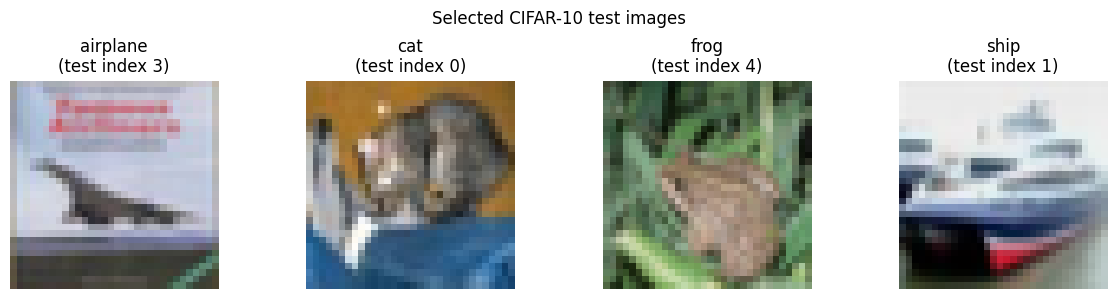

In [3]:
(_, _), (test_images_raw, y_test_raw) = cifar10.load_data()
y_test = y_test_raw.squeeze().astype(np.int64)

assert test_images_raw.shape == (10000, 32, 32, 3)
assert y_test.shape == (10000,)

classes_to_inspect = ["airplane", "cat", "frog", "ship"]
class_to_index = {name: index for index, name in enumerate(class_names)}

test_indices = []
for class_name in classes_to_inspect:
    class_id = class_to_index[class_name]
    matches = np.flatnonzero(y_test == class_id)
    if len(matches) == 0:
        raise RuntimeError(f"No test image found for class {class_name!r}")
    test_indices.append(int(matches[0]))

normalization = config["dataset"]["normalization"]
mean = np.asarray(normalization["mean"], dtype=np.float32).reshape(1, 1, 1, 3)
std = np.asarray(normalization["std"], dtype=np.float32).reshape(1, 1, 1, 3)

selected_raw = test_images_raw[test_indices]
selected_nhwc = selected_raw.astype(np.float32) / 255.0
selected_nhwc = (selected_nhwc - mean) / std
x_selected = np.ascontiguousarray(selected_nhwc.transpose(0, 3, 1, 2))
y_selected = y_test[test_indices]

fig, axes = plt.subplots(1, len(test_indices), figsize=(12, 3))
for ax, image, label, index in zip(axes, selected_raw, y_selected, test_indices):
    ax.imshow(image)
    ax.set_title(f"{class_names[label]}\n(test index {index})")
    ax.axis("off")

fig.suptitle("Selected CIFAR-10 test images")
fig.tight_layout()
plt.show()

In [4]:
conv1_output = conv2d_nchw(
    x_selected, conv1_weights, conv1_bias, padding="same"
)
conv1_relu = np.maximum(conv1_output, 0)
pool1_output = max_pool2d_nchw(conv1_relu)

conv2_output = conv2d_nchw(
    pool1_output, conv2_weights, conv2_bias, padding="same"
)
conv2_relu = np.maximum(conv2_output, 0)
pool2_output = max_pool2d_nchw(conv2_relu)

assert conv1_relu.shape == (len(test_indices), 16, 32, 32)
assert pool1_output.shape == (len(test_indices), 16, 16, 16)
assert conv2_relu.shape == (len(test_indices), 32, 16, 16)
assert pool2_output.shape == (len(test_indices), 32, 8, 8)

logits = pool2_output.reshape(len(test_indices), -1) @ dense_weights.T + dense_bias
predictions = logits.argmax(axis=1)

for class_name, actual, predicted in zip(
    classes_to_inspect, y_selected, predictions
):
    print(
        f"Actual: {class_name:>10} | "
        f"Predicted: {class_names[predicted]:>10} | "
        f"{'correct' if actual == predicted else 'incorrect'}"
    )

Actual:   airplane | Predicted:   airplane | correct
Actual:        cat | Predicted:        cat | correct
Actual:       frog | Predicted:       frog | correct
Actual:       ship | Predicted:       ship | correct


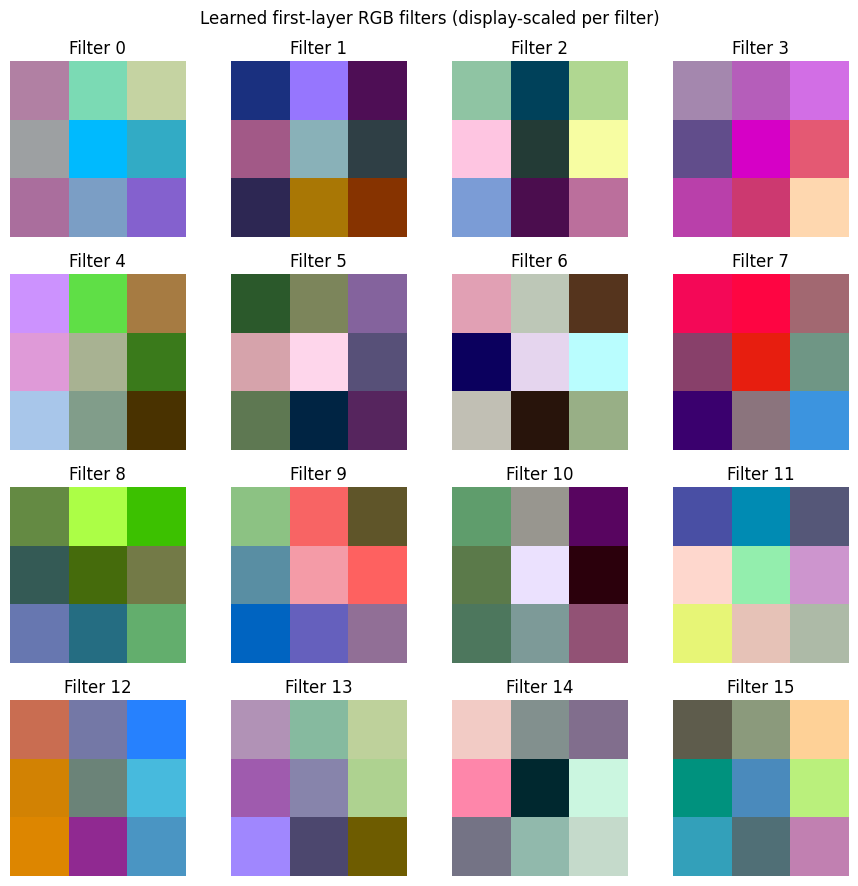

In [5]:
fig, axes = plt.subplots(4, 4, figsize=(9, 9))

for filter_index, ax in enumerate(axes.flat):
    rgb_filter = conv1_weights[filter_index].transpose(1, 2, 0)

    # Per-filter contrast scaling helps reveal structure; it is for display only.
    low = rgb_filter.min()
    high = rgb_filter.max()
    display_filter = (rgb_filter - low) / (high - low + 1e-8)

    ax.imshow(display_filter)
    ax.set_title(f"Filter {filter_index}")
    ax.axis("off")

fig.suptitle("Learned first-layer RGB filters (display-scaled per filter)")
fig.tight_layout()
plt.show()

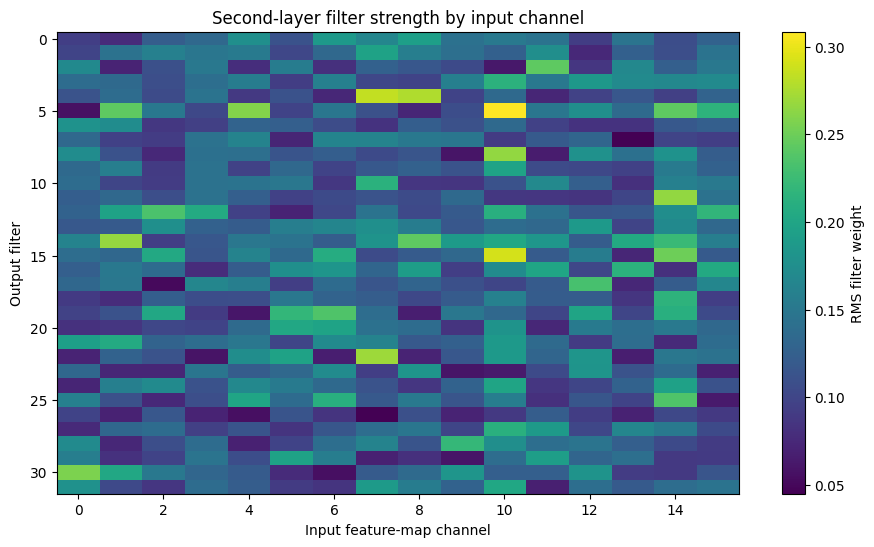

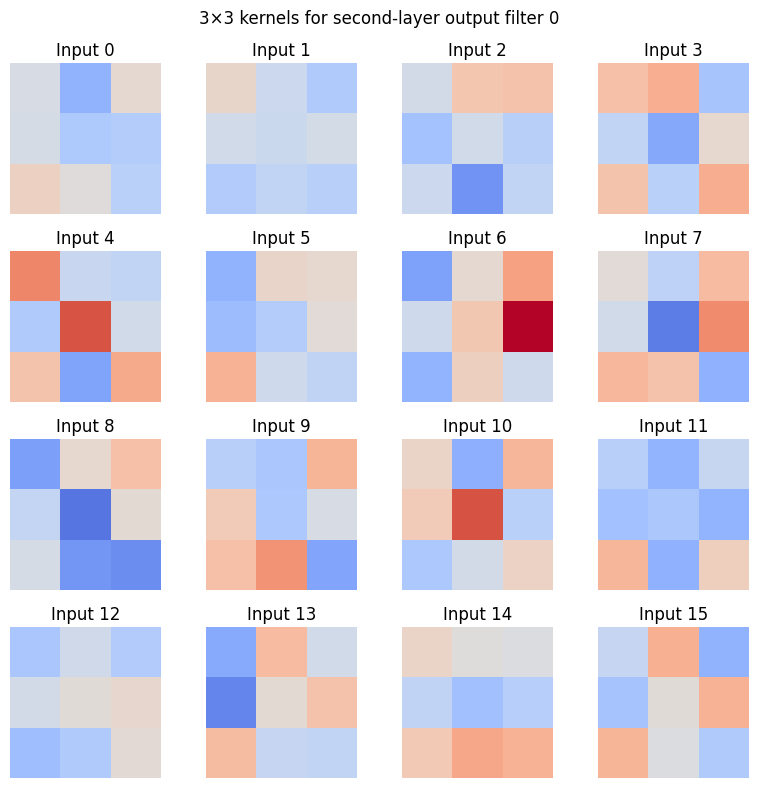

In [6]:
# Each cell shows the RMS weight strength connecting one input channel
# to one output-channel filter.
channel_strength = np.sqrt(np.mean(conv2_weights**2, axis=(2, 3)))

fig, ax = plt.subplots(figsize=(11, 6))
image = ax.imshow(channel_strength, aspect="auto", cmap="viridis")
fig.colorbar(image, ax=ax, label="RMS filter weight")
ax.set(
    xlabel="Input feature-map channel",
    ylabel="Output filter",
    title="Second-layer filter strength by input channel",
)
plt.show()

# Show the individual 3x3 kernels for all 16 input channels of one output filter.
output_filter_index = 0
kernel_bank = conv2_weights[output_filter_index]
limit = np.max(np.abs(kernel_bank)) + 1e-8

fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for channel_index, ax in enumerate(axes.flat):
    ax.imshow(
        kernel_bank[channel_index],
        cmap="coolwarm",
        vmin=-limit,
        vmax=limit,
    )
    ax.set_title(f"Input {channel_index}")
    ax.axis("off")

fig.suptitle(f"3×3 kernels for second-layer output filter {output_filter_index}")
fig.tight_layout()
plt.show()

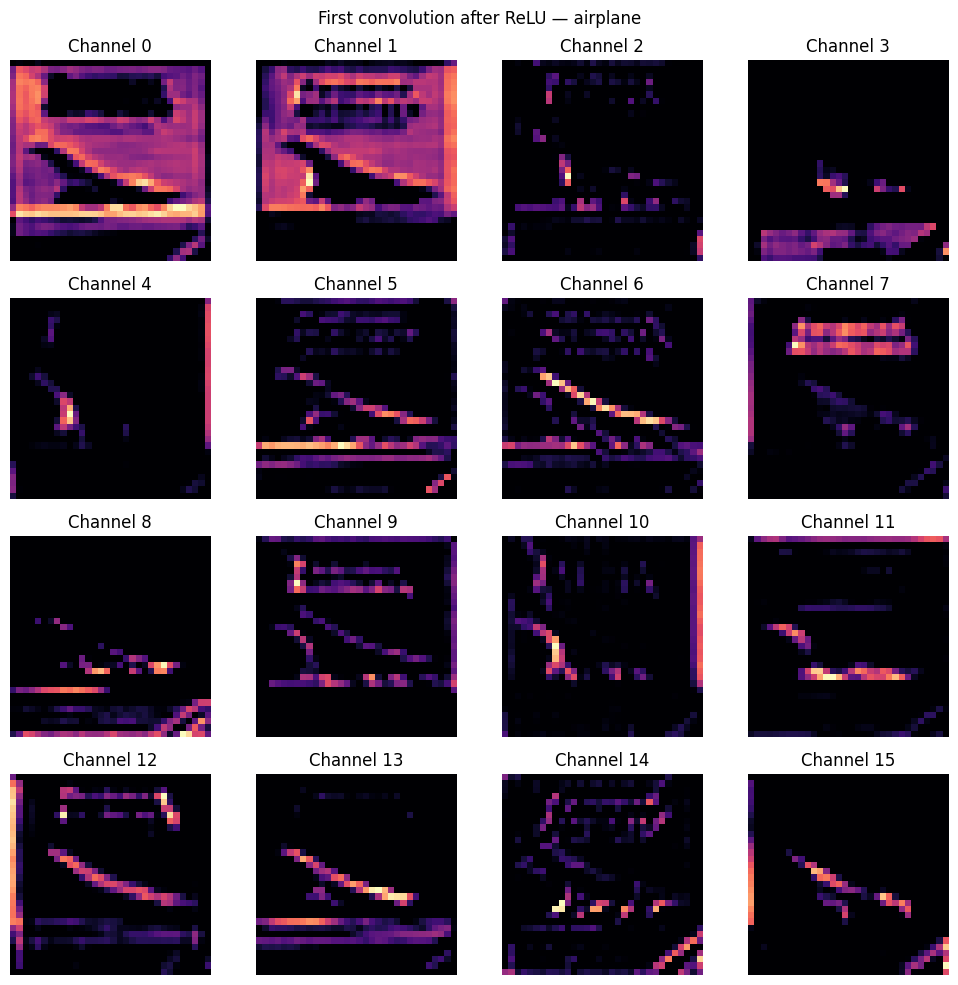

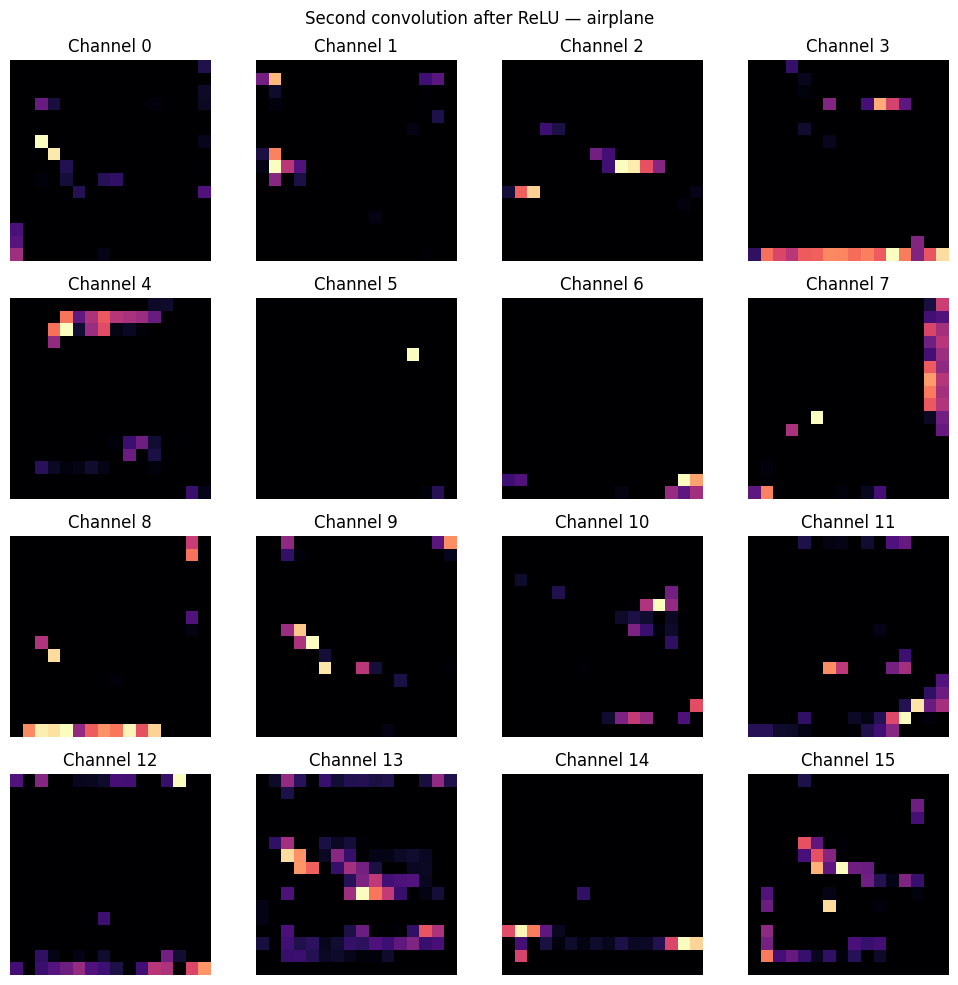

In [7]:
image_position = 0
feature_groups = [
    ("First convolution after ReLU", conv1_relu, 16),
    ("Second convolution after ReLU", conv2_relu, 32),
]

for title, activations, max_maps in feature_groups:
    number_to_show = min(16, max_maps)
    columns = 4
    rows = int(np.ceil(number_to_show / columns))

    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=(10, 2.5 * rows),
        squeeze=False,
    )

    for channel_index, ax in enumerate(axes.flat):
        if channel_index < number_to_show:
            feature_map = activations[image_position, channel_index]
            ax.imshow(feature_map, cmap="magma")
            ax.set_title(f"Channel {channel_index}")
        ax.axis("off")

    fig.suptitle(
        f"{title} — {class_names[y_selected[image_position]]}"
    )
    fig.tight_layout()
    plt.show()

In [8]:
image_position = 0
channel_index = 0
surface = conv1_relu[image_position, channel_index]

fig = go.Figure(
    data=[
        go.Surface(
            z=surface,
            colorscale="Viridis",
            colorbar={"title": "Activation"},
        )
    ]
)
fig.update_layout(
    title=(
        f"3D first-layer activation surface — "
        f"{class_names[y_selected[image_position]]}, channel {channel_index}"
    ),
    scene={
        "xaxis_title": "Pixel x",
        "yaxis_title": "Pixel y",
        "zaxis_title": "Activation",
    },
    height=650,
)
fig.show()

In [9]:
# Treat channels as the third spatial axis. The volume is (height, width, channels).
volume = pool2_output[image_position].transpose(1, 2, 0)
positive_values = volume[volume > 0]

if positive_values.size == 0:
    print("The selected image has no positive activations in the final feature volume.")
else:
    height, width, channels = volume.shape
    grid_y, grid_x, grid_channel = np.mgrid[
        0:height,
        0:width,
        0:channels,
    ]

    isomin = float(np.percentile(positive_values, 50))
    isomax = float(positive_values.max())
    if isomin >= isomax:
        isomin = isomax * 0.5

    fig = go.Figure(
        data=[
            go.Volume(
                x=grid_x.ravel(),
                y=grid_y.ravel(),
                z=grid_channel.ravel(),
                value=volume.ravel(),
                isomin=isomin,
                isomax=isomax,
                opacity=0.12,
                surface_count=12,
                colorscale="Viridis",
                colorbar={"title": "Activation"},
            )
        ]
    )
    fig.update_layout(
        title=(
            f"3D pooled activation volume — "
            f"{class_names[y_selected[image_position]]}"
        ),
        scene={
            "xaxis_title": "Pixel x",
            "yaxis_title": "Pixel y",
            "zaxis_title": "Feature channel",
        },
        height=700,
    )
    fig.show()